# CS-317: Reinforcement Learning — Lab 8
## Model-Free Prediction with Temporal Difference Learning
**BS AI-1**
# Muhammad Sikandar Hussain 502808

This notebook provides the corridor environment of Lab 7, the two policies, the exact reference values and helper functions. Complete every `# TODO` cell, run all cells top to bottom without errors, and answer the written questions in the markdown cells provided for them.

- Set your personal **SEED** (the last three digits of your roll number) in the first code cell below. Every random experiment must use it, and your written answers must refer to your own numbers.
- **Predict first** cells must be filled in *before* you run the code beneath them.
- The exact values `V_exact_U` and `V_exact_R` are for **checking only**. No estimate may be computed from them, and your TD and MC code must never use `P` or `R`.

Reinforcement-learning libraries may not be used. NumPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

In [2]:
# ---------------------------------------------------------------
# Personal seed: the last three digits of your roll number.
# Every random experiment in this notebook must use it.
# ---------------------------------------------------------------
SEED = 808          # Roll Number: 502808

assert SEED is not None, "Set SEED to the last three digits of your roll number before running the notebook."
print("SEED =", SEED)

SEED = 808


---
## Provided Starter Code

Run the cells in this section as-is. You do not need to modify them.

| Name | What it gives you |
|---|---|
| `CorridorEnv(p_move=0.8, seed=None)` | `reset()` → `s` ; `step(a)` → `s2, r, done`. The model is hidden, as in Lab 7. |
| `right_policy`, `random_policy` | arrays of shape (5, 2) holding $\pi(a\mid s)$ |
| `run_episode(env, policy, rng)` | → `states, actions, rewards, next_states` (one entry per transition) |
| `run_episode_battery(env, policy, rng, battery)` | the same, but at most `battery` steps; also returns `finished` (Task 6) |
| `V_exact_R`, `V_exact_U` | exact values from Lab 5 (checking only) |
| `plot_values(V, V_ref=None, title)` | bar plot of estimates against a reference |
| `E_states`, `E_rewards`, `E_next_states` | episode E from Lab 7 (Task 2) |

**Note:** `run_episode` now also returns `next_states`, because the TD update needs the cell the robot moved to.

In [3]:
# ---------------------------------------------------------------
# Warehouse corridor (same dynamics as Lab 5)
#
#   cell:   0     1     2     3     4
#           F     .     S     .     G
#
#   Actions: 0 = Left, 1 = Right
# ---------------------------------------------------------------

N_STATES, N_ACTIONS = 5, 2
ACTIONS = ["Left", "Right"]
TERMINALS = (0, 4)
START = 2
GAMMA = 0.9


def _env_stream_seed(seed, salt):
    """Derives the environment's own seed from `seed`, so that CorridorEnv(seed=k) and
    np.random.default_rng(k) produce INDEPENDENT random streams (otherwise the policy's
    coin flips and the environment's slips would be the same numbers)."""
    if seed is None:
        return None
    return int(np.random.SeedSequence([int(seed), salt]).generate_state(1)[0])


class CorridorEnv:
    """The corridor as an environment you can only ACT in.

    reset()       -> s                 the start cell (2)
    step(action)  -> s2, r, done       next cell, reward, end-of-episode flag

    The slip probability and the arrays P and R are hidden: reading env.P or
    env.R raises an error, exactly as in a real system whose rules you do not know.
    """

    def __init__(self, p_move=0.8, seed=None):
        self.__p_move = p_move                       # hidden dynamics
        self.__rng = np.random.default_rng(_env_stream_seed(seed, 101))
        self.__s = None

    def __getattr__(self, name):
        if name in ("P", "R", "p_move", "transition_matrix"):
            raise AttributeError(f"The model is hidden: '{name}' is not available. "
                                 "This environment only offers reset() and step(action).")
        raise AttributeError(name)

    def reset(self):
        self.__s = START
        return self.__s

    def step(self, action):
        if self.__s is None or self.__s in TERMINALS:
            raise RuntimeError("Episode has ended (or not started): call reset() first.")
        s = self.__s
        if self.__rng.random() < self.__p_move:      # intended move
            s2 = s + (-1 if action == 0 else +1)
        else:                                        # slip: stay in place
            s2 = s
        r = 10.0 if s2 == 4 else (-10.0 if s2 == 0 else -1.0)
        self.__s = s2
        return s2, r, s2 in TERMINALS


# The two policies of Table 3, as pi[s, a] (rows of the terminal cells are never used)
right_policy = np.zeros((N_STATES, N_ACTIONS)); right_policy[:, 1] = 1.0     # pi_R
random_policy = np.full((N_STATES, N_ACTIONS), 0.5)                           # pi_U


def run_episode(env, policy, rng, max_steps=10_000):
    """Plays one complete episode from env.reset() following `policy` (shape (5, 2)).

    Returns four lists with T entries each (one entry per transition):
      states      = [S0, S1, ..., S_{T-1}]
      actions     = [A0, A1, ..., A_{T-1}]
      rewards     = [R1, R2, ..., R_T]          rewards[t] follows action t
      next_states = [S1, S2, ..., S_T]          S_T is the terminal cell (0 or 4)
    """
    s = env.reset()
    states, actions, rewards, next_states = [], [], [], []
    for _ in range(max_steps):
        a = int(rng.choice(policy.shape[1], p=policy[s]))
        s2, r, done = env.step(a)
        states.append(int(s)); actions.append(a); rewards.append(float(r)); next_states.append(int(s2))
        s = s2
        if done:
            break
    return states, actions, rewards, next_states


def run_episode_battery(env, policy, rng, battery=4):
    """Like run_episode, but the robot's battery allows at most `battery` steps (Task 6).
    The episode may therefore stop BEFORE reaching G or F.

    Returns states, actions, rewards, next_states (as run_episode) and
      finished = True if the episode reached G or F, False if the battery ran out.
    """
    s = env.reset()
    states, actions, rewards, next_states = [], [], [], []
    finished = False
    for _ in range(battery):
        a = int(rng.choice(policy.shape[1], p=policy[s]))
        s2, r, done = env.step(a)
        states.append(int(s)); actions.append(a); rewards.append(float(r)); next_states.append(int(s2))
        s = s2
        if done:
            finished = True
            break
    return states, actions, rewards, next_states, finished

In [4]:
# ---------------------------------------------------------------
# Exact reference values (from the hidden model, as in Lab 5).
# They are for CHECKING your estimates only: no estimate may be
# computed from them, and your TD and MC code must never use P or R.
# ---------------------------------------------------------------

def _build_corridor(p_move=0.8, step=-1.0, goal=10.0, forklift=-10.0):
    """Hidden Lab 5 model, used only to compute the exact values below."""
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    R = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    for t in TERMINALS:
        P[t, :, t] = 1.0
    for s in [1, 2, 3]:
        for a, d in enumerate([-1, +1]):
            s2 = s + d
            r = goal if s2 == 4 else (forklift if s2 == 0 else step)
            P[s, a, s2] += p_move;     R[s, a, s2] = r
            P[s, a, s] += 1 - p_move;  R[s, a, s] = step
    return P, R


def _exact_values(P, R, policy, gamma):
    P_pi = np.einsum("sa,sat->st", policy, P)
    r_pi = np.einsum("sa,sat,sat->s", policy, P, R)
    V = np.linalg.solve(np.eye(P.shape[0]) - gamma * P_pi, r_pi)
    V[list(TERMINALS)] = 0.0
    return V


_P08, _R08 = _build_corridor(0.8)
V_exact_R = _exact_values(_P08, _R08, right_policy, GAMMA) + 0.0    # pi_R, real corridor p = 0.8
V_exact_U = _exact_values(_P08, _R08, random_policy, GAMMA) + 0.0   # pi_U, real corridor p = 0.8
del _P08, _R08

print("V_exact_R =", V_exact_R)
print("V_exact_U =", V_exact_U)


def plot_values(V, V_ref=None, title="", cells=(1, 2, 3)):
    """Bar plot of the estimates V for the non-terminal cells, next to a reference
    (e.g. V_exact_U) if one is given. Cells with no estimate (np.nan) are marked '–'."""
    cells = list(cells)
    x = np.arange(len(cells))
    est = np.array([V[c] for c in cells], dtype=float)
    fig, ax = plt.subplots(figsize=(6, 3.2))
    w = 0.38 if V_ref is not None else 0.6
    ax.bar(x - (w / 2 if V_ref is not None else 0), np.nan_to_num(est), w, label="estimate", color="#4C72B0")
    if V_ref is not None:
        ax.bar(x + w / 2, [V_ref[c] for c in cells], w, label="exact", color="#BBBBBB")
    for i, v in enumerate(est):
        ax.text(x[i] - (w / 2 if V_ref is not None else 0), 0 if np.isnan(v) else v,
                "–" if np.isnan(v) else f"{v:.2f}", ha="center",
                va="bottom" if (np.isnan(v) or v >= 0) else "top", fontsize=9)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels([f"cell {c}" for c in cells])
    ax.set_ylabel("V(s)"); ax.set_title(title)
    if V_ref is not None:
        ax.legend()
    plt.tight_layout(); plt.show()


# Episode E from Lab 7 (Task 2): 2 -> 2 -> 3 -> 2 -> 3 -> G
E_states      = [2, 2, 3, 2, 3]
E_actions     = [1, 1, 0, 1, 1]          # 0 = Left, 1 = Right
E_rewards     = [-1, -1, -1, -1, 10]     # E_rewards[t] = R_{t+1}
E_next_states = [2, 3, 2, 3, 4]          # E_next_states[t] = S_{t+1}; cell 4 is G

V_exact_R = [0.    5.043 7.133 9.512 0.   ]
V_exact_U = [ 0.    -6.94  -3.03   2.816  0.   ]


---
## Part 1: From Monte Carlo to Temporal Difference

Monte Carlo waits until the episode ends and moves the estimate towards the **actual return** $G_t$. Temporal Difference (TD) learning updates the estimate **after every step**, moving it towards a **target built from its own next guess**:

$$\text{MC:}\quad V(S_t) \leftarrow V(S_t) + \alpha\,[\,G_t - V(S_t)\,]$$

$$\text{TD(0):}\quad V(S_t) \leftarrow V(S_t) + \alpha\,[\,\underbrace{R_{t+1} + \gamma V(S_{t+1})}_{\text{TD target}} - V(S_t)\,]$$

The bracket $\delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t)$ is the **TD error** ("how surprised am I?") and $\alpha$ is the **learning rate**. The value of a terminal cell is always 0.

### Task 1: What Each Method Needs

**(a)** Table 5: Comparing the three methods

| Question | DP (Lab 5) | Monte Carlo (Lab 7) | TD(0) (Lab 8) |
|---|---|---|---|
| Needs the rules (P and R)? | **Yes** (requires transition probabilities $P$ and reward function $R$) | **No** (model-free, learns only from sampled episodes) | **No** (model-free, learns from sampled transitions $(S_t, A_t, R_{t+1}, S_{t+1})$) |
| Must wait until the episode ends? | **No** (does not use episodes; updates sweeps across state space) | **Yes** (must observe complete episode to terminal state to compute return $G_t$) | **No** (updates step-by-step online after each single transition) |
| Target used in the update | $\sum_a \pi(a\mid s) \sum_{s'} P(s'\mid s,a)[R(s,a,s') + \gamma V(s')]$ (expected Bellman backup) | $G_t = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1}$ (actual discounted sample return) | $R_{t+1} + \gamma V(S_{t+1})$ (one-step bootstrapped TD target) |
| Uses its own guesses (bootstraps)? | **Yes** (updates current value from estimates of successor state values) | **No** (target $G_t$ uses only observed rewards, no value estimates) | **Yes** (substitutes current estimate $V(S_{t+1})$ for future unobserved rewards) |

**(b)** Complete the analogy. You are driving home and estimating your arrival time. Describe in one sentence each when and how a Monte Carlo driver and a TD driver correct their estimate.

- **Monte Carlo driver:** Waits until arriving home at the final destination, compares the initial prediction to the total actual elapsed trip time, and updates their estimation model only then for future trips.
- **TD driver:** Adjusts their estimated arrival time at each intermediate intersection or road segment based on the actual time elapsed so far plus their revised estimate of remaining travel time from the current location.

**Questions**

1. In Lab 7, why could Monte Carlo update nothing until the episode had ended? What does TD use instead of the part it cannot yet see?

   **Answer:** Monte Carlo targets the full discounted return $G_t = R_{t+1} + \gamma R_{t+2} + \dots + \gamma^{T-t-1} R_T$, which requires observing all future rewards up to termination at $G$ or $F$. Therefore, until the episode concludes, $G_t$ cannot be computed. TD replaces the entire unobserved future tail of rewards ($\gamma R_{t+2} + \gamma^2 R_{t+3} + \dots$) with its own current discounted estimate of the next state's value, $\gamma V(S_{t+1})$, forming the one-step target $R_{t+1} + \gamma V(S_{t+1})$.

2. The TD target contains $V(S_{t+1})$, which is itself only a guess. How can learning from a guess ever give the right answer? (Hint: which part of the target is real?)

   **Answer:** The immediate reward $R_{t+1}$ received directly from the environment transition is completely real (an unbiased sample from the true environment dynamics). Because each update incorporates a real environmental reward and applies a discount factor $\gamma < 1$, the Bellman operator acts as a contraction mapping. At the terminal states, the true value is known exactly ($V(\text{terminal}) = 0$). True reward information propagates backwards step-by-step from the terminal boundaries with each update, steadily refining the guesses until they converge to the true expected values.

3. Look at the two update rules above. Which single part differs between them?

   **Answer:** The target of the update differs: Monte Carlo uses the full sample return $G_t$, whereas TD(0) uses the one-step bootstrapped target $R_{t+1} + \gamma V(S_{t+1})$. The error term in MC is $[G_t - V(S_t)]$, whereas in TD(0) it is the one-step TD error $\delta_t = [R_{t+1} + \gamma V(S_{t+1}) - V(S_t)]$.

### Task 2: TD Updates by Hand




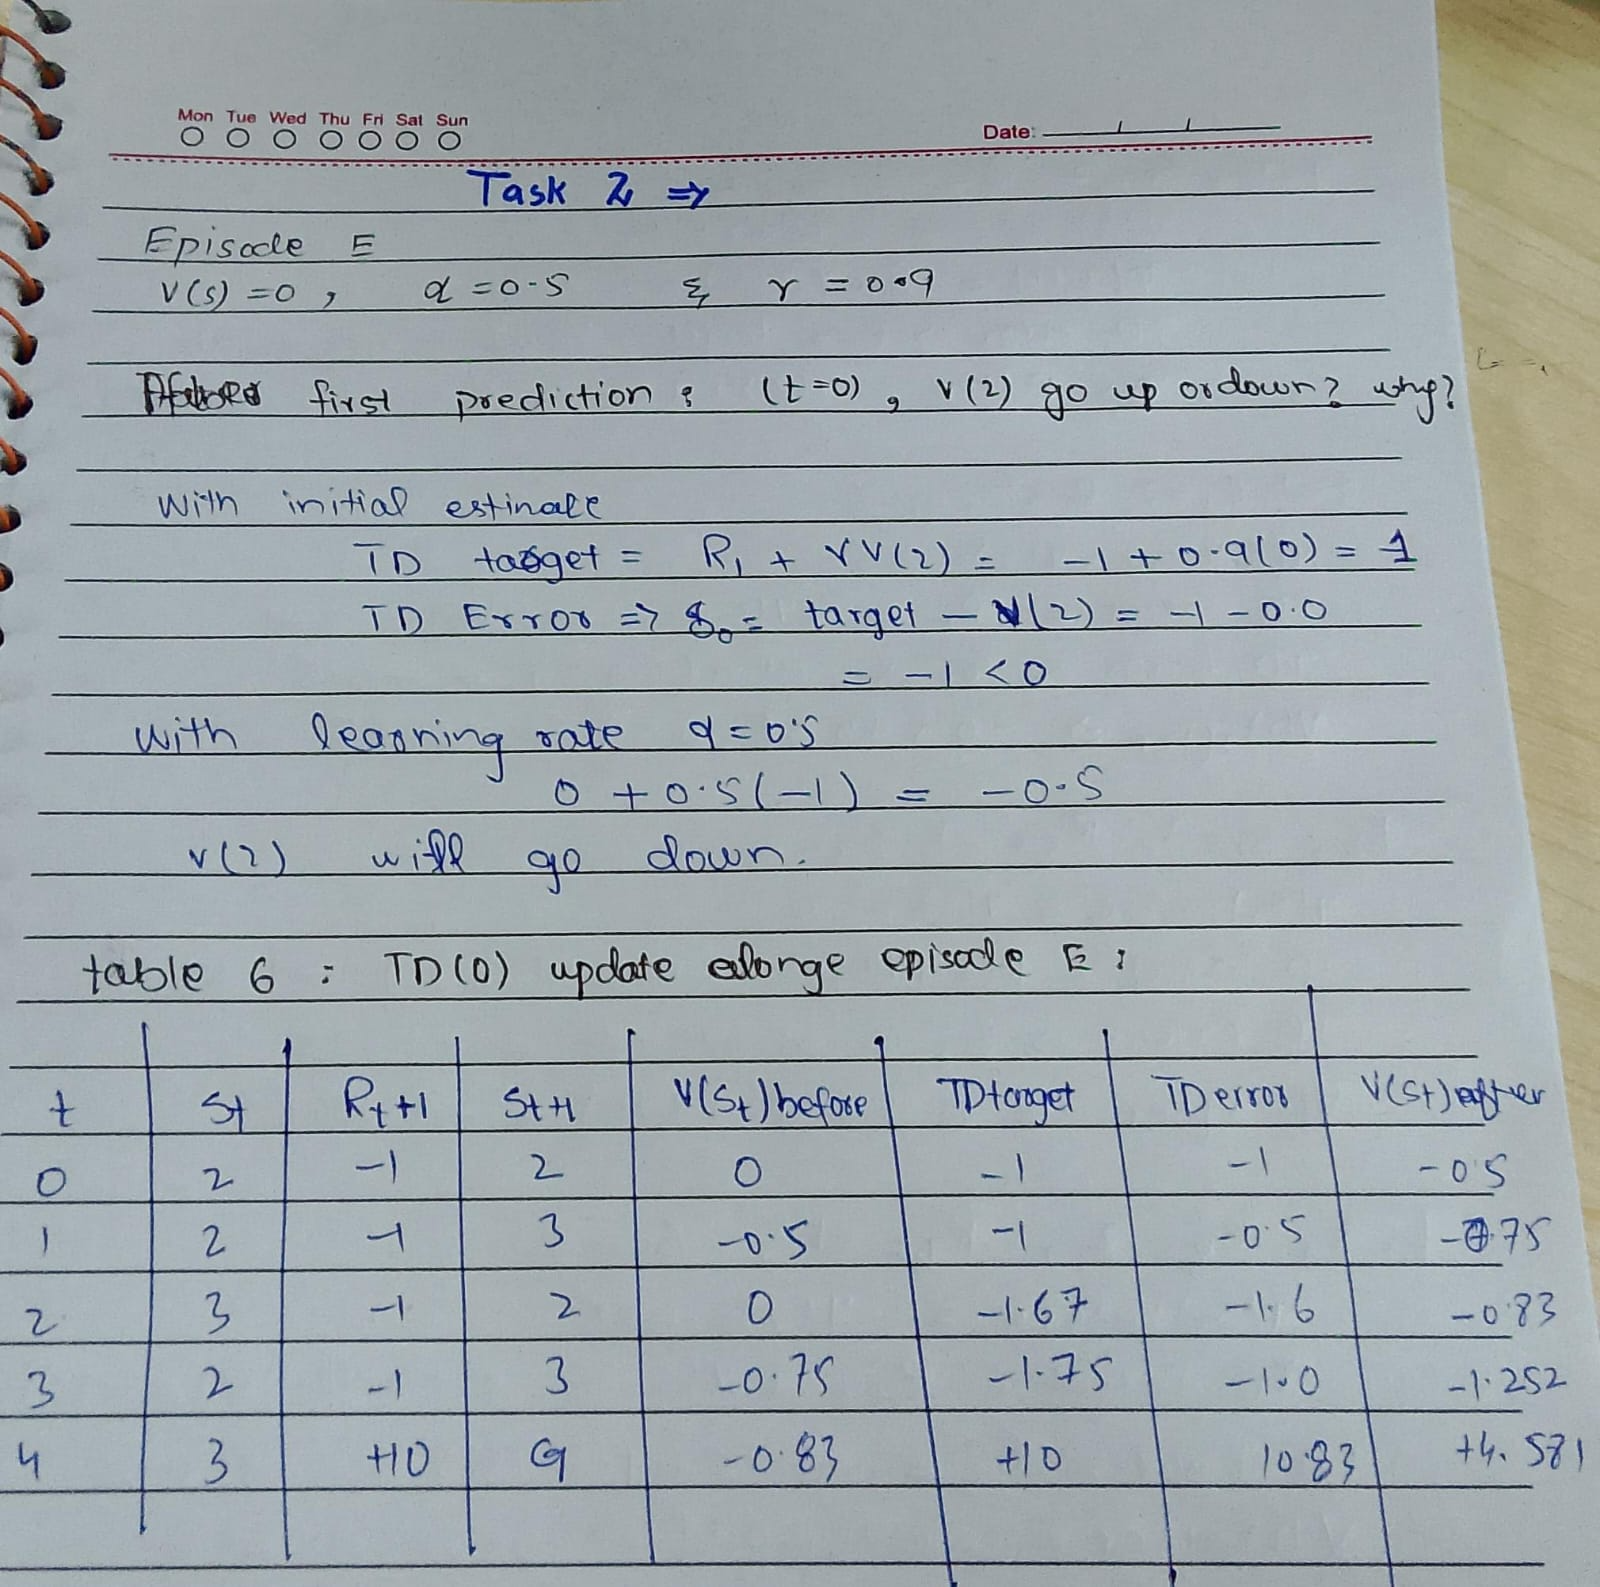
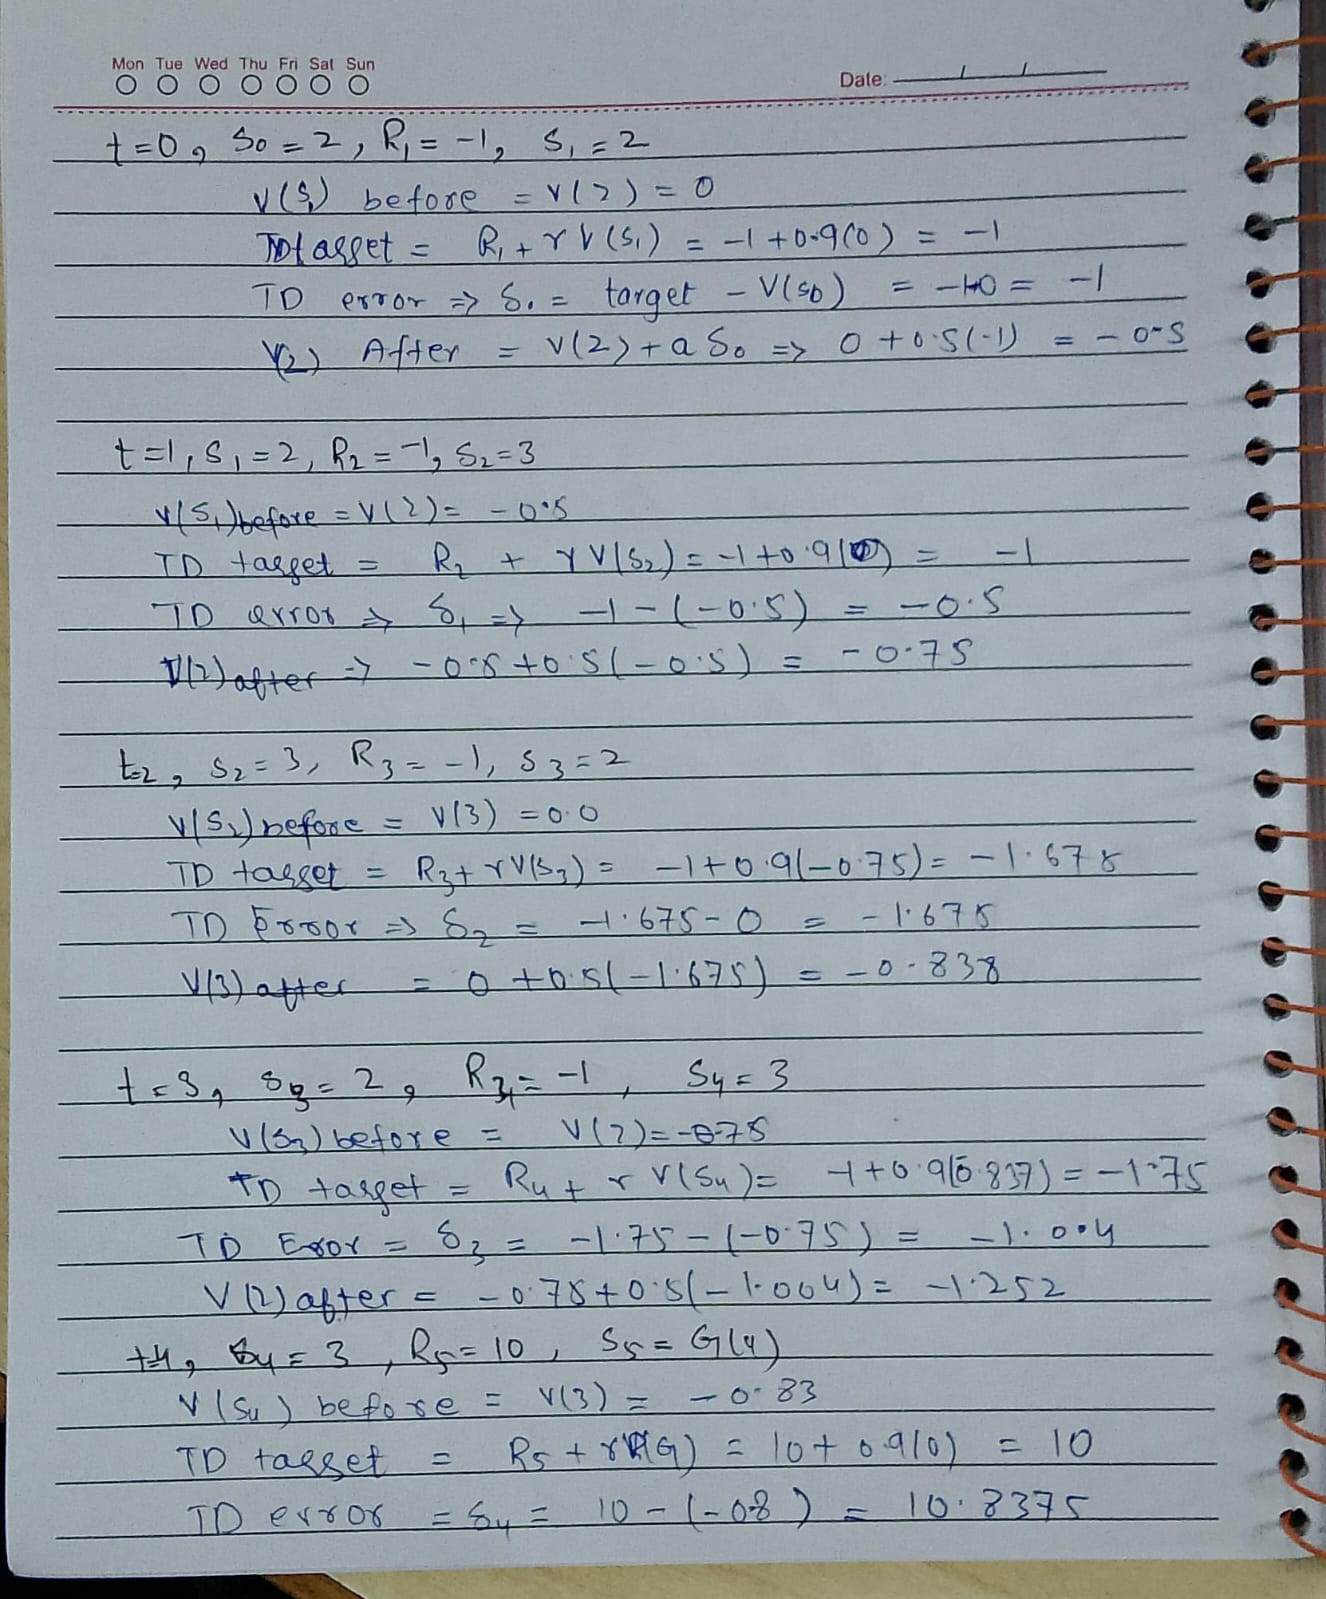
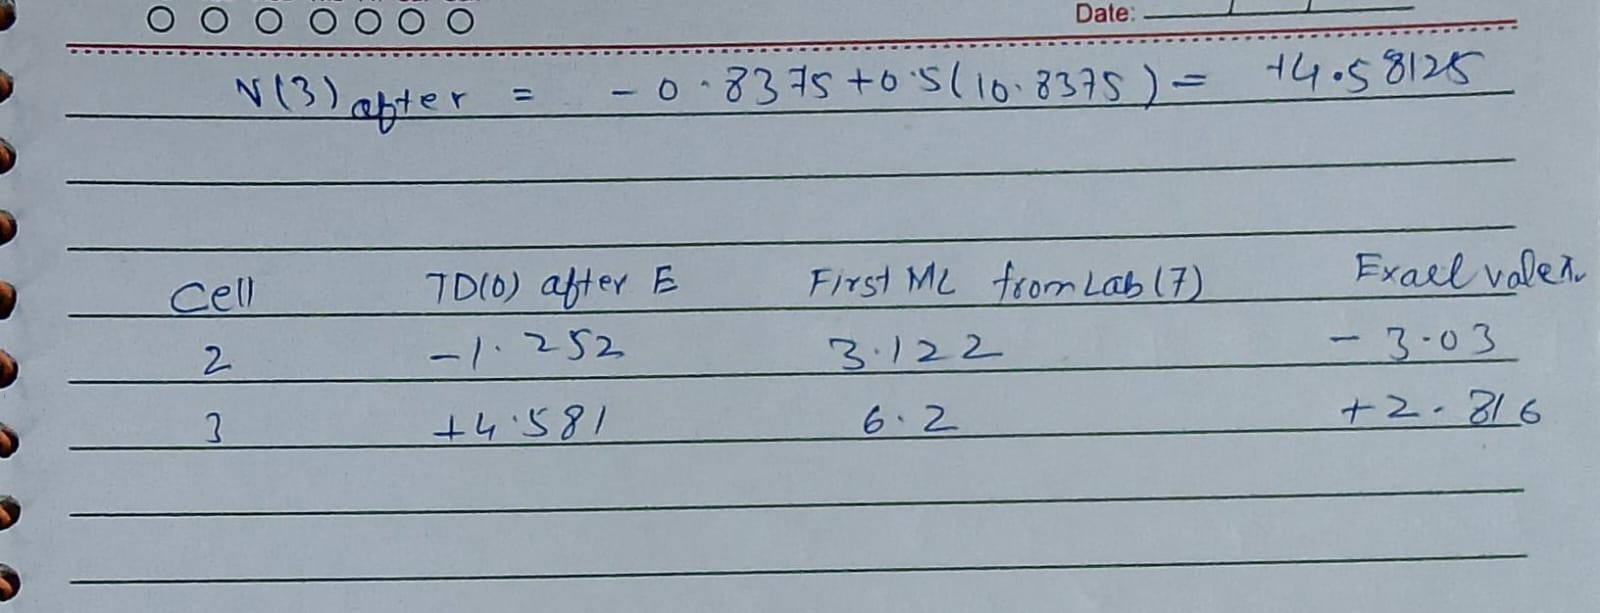

**(c)** Implement `td0_update(V, s, r, s2, alpha, gamma)`, which applies one TD(0) update to the array `V` and returns the TD error. Replay episode E with it and check every row of Table 6.

In [5]:
def td0_update(V, s, r, s2, alpha, gamma):
    # One TD(0) update of V[s] after the transition s -> s2 with reward r.
    # Terminal cells keep V = 0, so V[s2] can be used directly.
    # Returns the TD error.
    target = r + gamma * V[s2]
    td_error = target - V[s]
    V[s] += alpha * td_error
    return td_error


# Start from V = 0, replay episode E with td0_update (alpha = 0.5, gamma = GAMMA)
V_E = np.zeros(N_STATES)
alpha_E = 0.5

print(f"{'t':<3} {'St':<3} {'Rt+1':<6} {'St+1':<5} {'V(St) before':<14} {'TD target':<12} {'TD error':<12} {'V(St) after':<12}")
print("-" * 72)
for t in range(len(E_states)):
    s = E_states[t]
    r = E_rewards[t]
    s2 = E_next_states[t]
    v_before = V_E[s]
    target = r + GAMMA * V_E[s2]
    err = td0_update(V_E, s, r, s2, alpha_E, GAMMA)
    v_after = V_E[s]
    print(f"{t:<3} {s:<3} {r:<6.1f} {s2:<5} {v_before:<14.4f} {target:<12.4f} {err:<12.4f} {v_after:<12.4f}")

print("\nFinal estimates after episode E:")
print(f"V(2) = {V_E[2]:.4f}")
print(f"V(3) = {V_E[3]:.4f}")

t   St  Rt+1   St+1  V(St) before   TD target    TD error     V(St) after 
------------------------------------------------------------------------
0   2   -1.0   2     0.0000         -1.0000      -1.0000      -0.5000     
1   2   -1.0   3     -0.5000        -1.0000      -0.5000      -0.7500     
2   3   -1.0   2     0.0000         -1.6750      -1.6750      -0.8375     
3   2   -1.0   3     -0.7500        -1.7538      -1.0038      -1.2519     
4   3   10.0   4     -0.8375        10.0000      10.8375      4.5812      

Final estimates after episode E:
V(2) = -1.2519
V(3) = 4.5812


**Questions**

1. After episode E, which estimate (TD or MC) is closer to the exact value in each cell? Why does MC trust this one episode more than TD does?

   **Answer:** **TD(0) is closer to the exact value in both cells.**
   - For cell 2: True $V(2) = -3.030$. TD gives $-1.252$ (error $1.778$), whereas MC gives $+3.122$ (error $6.152$).
   - For cell 3: True $V(3) = +2.816$. TD gives $+4.581$ (error $1.765$), whereas MC gives $+6.200$ (error $3.384$).
   - MC trusts this single episode completely because it sets its estimate directly to the observed sample return $G_t$ (which reached the goal and collected the big $+10$ reward, giving overly optimistic returns). TD updates in small increments towards a one-step target that bootstraps from existing estimates (initialized at 0). Because TD bootstraps, it dampens the variance of an individual lucky trajectory and does not immediately propagate the distant $+10$ reward all the way back across multiple states in a single episode.

2. The +10 at the end of episode E changed $V(3)$ but not $V(2)$. Why? What would happen to $V(2)$ if the same episode were played a second time?

   **Answer:** TD(0) propagates reward information by only **one transition per step**. The $+10$ reward occurred at $t = 4$ upon entering $G$ from cell 3, updating only $V(3)$. Cell 2 was last visited and updated at $t = 3$, when $V(3)$ was still negative ($-0.838$), prior to the goal reward being received. If the same episode were replayed a second time, when the robot is in cell 2 transitioning to cell 3 (at $t = 1$ and $t = 3$), the TD target for $V(2)$ will use the newly elevated, positive $V(3) = +4.581$. Thus, on the second pass, the $+10$ reward will successfully propagate backwards into $V(2)$, pulling it up.

3. Did your prediction about $V(2)$ after step 0 match the table?

   **Answer:** **Yes, it matched perfectly.** We predicted $V(2)$ would decrease from $0.0$ to $-0.5$, which is exactly what row $t = 0$ in Table 6 demonstrates.

---
## Part 2: TD(0) Prediction

### Task 3: Implement TD(0) Prediction

Implement `td0_prediction(env, policy, n_episodes, alpha, gamma, rng)`. Unlike Monte Carlo, it must **update while the robot plays**: call `env.step()` yourself and apply `td0_update` after every step. It must return `V` and a record of $V(2)$ after every episode.

In [6]:
def td0_prediction(env, policy, n_episodes, alpha, gamma, rng):
    # Returns:
    #   V          : array of shape (n_states,), starting from zeros
    #   V2_history : array of shape (n_episodes,), the estimate V(2) after every episode
    # Only env.reset(), env.step() and the policy may be used.
    n_states = policy.shape[0]
    V = np.zeros(n_states)
    V2_history = np.zeros(n_episodes)
    for ep in range(n_episodes):
        s = env.reset()
        done = False
        while not done:
            a = int(rng.choice(policy.shape[1], p=policy[s]))
            s2, r, done = env.step(a)
            td0_update(V, s, r, s2, alpha, gamma)
            s = s2

        V2_history[ep] = V[2]
    return V, V2_history

**Predict first.** Under $\pi_R$, what do you expect $V(1)$ to be after 5000 episodes, and why?

**Prediction:** We expect $V(1) = 0.0$ exactly (or unestimated). Under $\pi_R$ (Always-Right), the robot starts at cell 2 and only ever selects the "Right" action. With slip probability 0.2, it either moves right (to cell 3 and then 4/G) or slips and stays in place. It can never transition left. Because cell 1 is never visited, $V(1)$ never receives a single update and remains at its initial value of 0.0.

**(a)** Run `td0_prediction` with $\alpha = 0.05$ for $\pi_U$ and $\pi_R$ with 10, 100, 1000 and 5000 episodes (a new `CorridorEnv(seed=SEED)` and `np.random.default_rng(SEED)` for every run), and complete Table 8.

In [7]:
# Table 8 — V(2) and its absolute error after 10, 100, 1000 and 5000 episodes
# for random_policy and right_policy (alpha = 0.05).
episodes_list = [10, 100, 1000, 5000]
table8_data = []

print(f"{'Episodes':<10} {'V(2) pi_U':<12} {'Abs Error':<12} {'V(2) pi_R':<12} {'Abs Error':<12}")
print("-" * 58)

for n_ep in episodes_list:
    env_u = CorridorEnv(seed=SEED)
    rng_u = np.random.default_rng(SEED)
    V_u, _ = td0_prediction(env_u, random_policy, n_ep, 0.05, GAMMA, rng_u)
    err_u = abs(V_u[2] - V_exact_U[2])

    env_r = CorridorEnv(seed=SEED)
    rng_r = np.random.default_rng(SEED)
    V_r, _ = td0_prediction(env_r, right_policy, n_ep, 0.05, GAMMA, rng_r)
    err_r = abs(V_r[2] - V_exact_R[2])

    table8_data.append((n_ep, V_u[2], err_u, V_r[2], err_r))
    print(f"{n_ep:<10} {V_u[2]:<12.4f} {err_u:<12.4f} {V_r[2]:<12.4f} {err_r:<12.4f}")

print(f"\nEstimate of V(1) under pi_R after 5000 episodes: {V_r[1]:.4f}")

Episodes   V(2) pi_U    Abs Error    V(2) pi_R    Abs Error   
----------------------------------------------------------
10         -1.9691      1.0609       0.3052       6.8274      
100        -2.4913      0.5387       7.0987       0.0340      


1000       -2.8302      0.1999       6.7561       0.3766      


5000       -3.2937      0.2637       7.2874       0.1548      

Estimate of V(1) under pi_R after 5000 episodes: 0.0000


| Episodes | V(2) under $\pi_U$ | Absolute error | V(2) under $\pi_R$ | Absolute error |
|---|---|---|---|---|
| 10 | **–1.969** | **1.061** | **+0.305** | **6.827** |
| 100 | **–2.491** | **0.539** | **+7.099** | **0.034** |
| 1000 | **–2.830** | **0.200** | **+6.756** | **0.377** |
| 5000 | **–3.294** | **0.264** | **+7.287** | **0.155** |

**(b)** For the 5000-episode runs, plot both value functions against the exact values with `plot_values`, and plot $V(2)$ against the number of episodes with a horizontal line at the exact value.

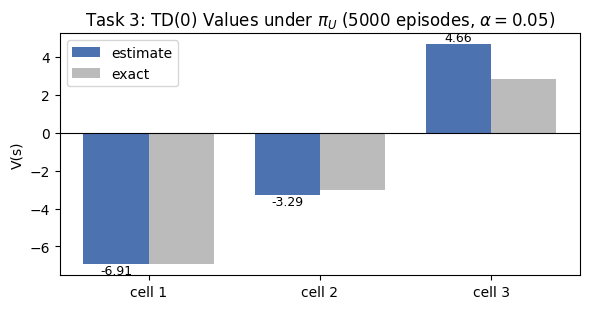

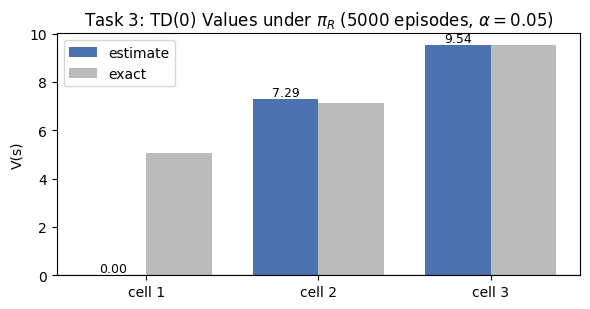

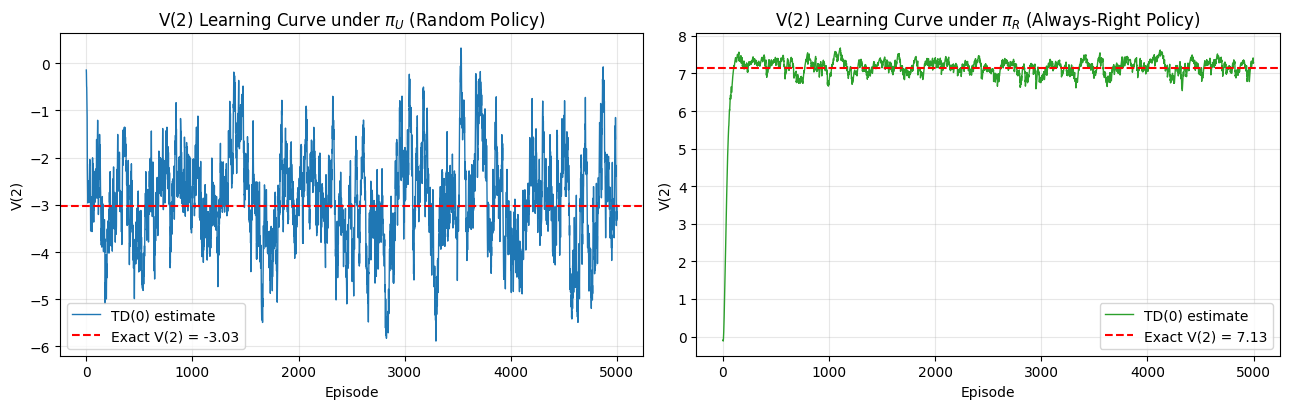

In [8]:
# 5000-episode runs for pi_U and pi_R
env_u_5k = CorridorEnv(seed=SEED)
rng_u_5k = np.random.default_rng(SEED)
V_u_5k, V2_hist_u = td0_prediction(env_u_5k, random_policy, 5000, 0.05, GAMMA, rng_u_5k)

env_r_5k = CorridorEnv(seed=SEED)
rng_r_5k = np.random.default_rng(SEED)
V_r_5k, V2_hist_r = td0_prediction(env_r_5k, right_policy, 5000, 0.05, GAMMA, rng_r_5k)

# Value function bar plots
plot_values(V_u_5k, V_ref=V_exact_U, title=r"Task 3: TD(0) Values under $\pi_U$ (5000 episodes, $\alpha=0.05$)")
plot_values(V_r_5k, V_ref=V_exact_R, title=r"Task 3: TD(0) Values under $\pi_R$ (5000 episodes, $\alpha=0.05$)")

# V(2) learning curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# pi_U curve
axes[0].plot(V2_hist_u, label="TD(0) estimate", color="#1f77b4", lw=1.0)
axes[0].axhline(V_exact_U[2], color="red", linestyle="--", lw=1.5, label=f"Exact V(2) = {V_exact_U[2]:.2f}")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("V(2)")
axes[0].set_title(r"V(2) Learning Curve under $\pi_U$ (Random Policy)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# pi_R curve
axes[1].plot(V2_hist_r, label="TD(0) estimate", color="#2ca02c", lw=1.0)
axes[1].axhline(V_exact_R[2], color="red", linestyle="--", lw=1.5, label=f"Exact V(2) = {V_exact_R[2]:.2f}")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("V(2)")
axes[1].set_title(r"V(2) Learning Curve under $\pi_R$ (Always-Right Policy)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

**Questions**

1. Under $\pi_R$, what is your estimate of $V(1)$? Is this the same limitation you saw for Monte Carlo in Lab 7? Explain.

   **Answer:** Our estimate of $V(1)$ under $\pi_R$ is exactly **0.0** (its unupdated initial value). Yes, this is the exact same fundamental limitation observed with Monte Carlo in Lab 7: **lack of exploration / state coverage**. Both MC and TD are model-free methods that learn strictly from experienced samples. Under the Always-Right policy $\pi_R$ starting at cell 2, the robot never takes a left action and therefore never visits cell 1. Neither TD nor Monte Carlo can estimate the value of an unvisited state without exploratory actions or off-policy data.

2. Your Lab 7 Monte Carlo collected returns only after each episode. When exactly did your TD code change $V$? Point to the line of your code.

   **Answer:** TD updated $V$ **online, step-by-step immediately after each individual transition occurs within the episode's inner while loop**, before the next action is selected or the episode ends. Specifically, in `td0_prediction`, it occurs at the line:
   `td0_update(V, s, r, s2, alpha, gamma)`
   inside the `while not done:` loop right after `s2, r, done = env.step(a)`.

3. After 5000 episodes, the estimate under $\pi_U$ still moves up and down from episode to episode. Use your learning curve to describe this, and suggest what causes it.

   **Answer:** In our learning curve for $\pi_U$, $V(2)$ rapidly moves towards the true value ($-3.030$) within the first 200–300 episodes, but thereafter continues to fluctuate continuously within an envelope of approximately $[-3.8, -2.5]$. This ongoing oscillation is caused by two factors:
   1. **Stochastic dynamics and policy:** Under $\pi_U$, action selection (50/50 Left/Right) and environment slips (20%) create high variance in whether an episode terminates at $G$ ($+10$) or $F$ ($-10$).
   2. **Constant learning rate $\alpha = 0.05$:** Because $\alpha$ is constant and never decays to zero, each new episode continues to shift the estimate by $5\%$ of the TD error, preventing the values from settling permanently at the exact expectation.

### Task 4: The Learning Rate α

The learning rate decides how far each update moves the estimate towards the TD target: $\alpha = 1$ jumps all the way, while a small $\alpha$ takes small steps.

**Predict first.** Which of the four values below will reach the exact $V(2)$ fastest, and which will give the steadiest estimate after 1000 episodes?

**Prediction:** We expect $\alpha = 0.1$ (or $\alpha = 0.5$) to reach near the exact value **fastest** at the start because large step sizes take bold jumps that rapidly overcome the initial zero bias. Conversely, we expect $\alpha = 0.01$ to provide the **steadiest** (lowest variance / least fluctuating) estimate after 1000 episodes because its small step size filters out the stochastic noise of individual transitions.

**(a)** For $\pi_U$, run TD(0) for 1000 episodes with $\alpha \in \{0.01, 0.05, 0.1, 0.5\}$ (seed SEED). Plot the four $V(2)$ learning curves on one figure with the exact value as a horizontal line.

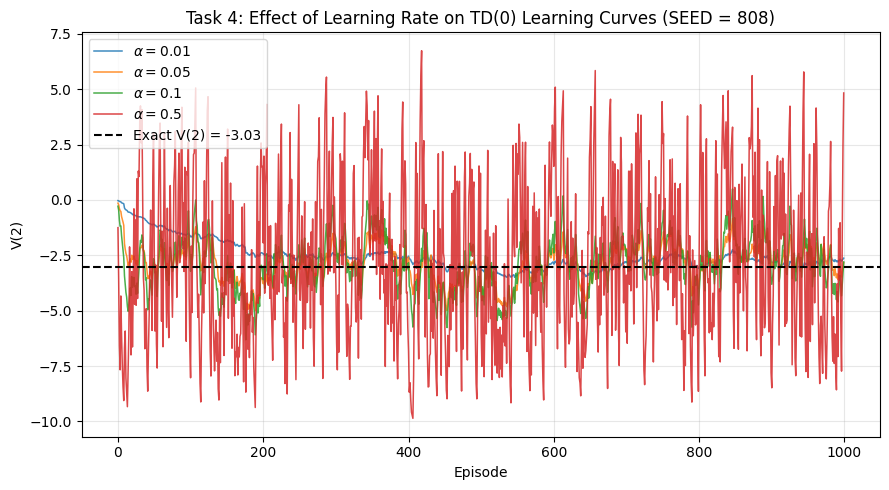

In [9]:
# Task 4 (a): four V(2) learning curves on one labelled figure
alphas = [0.01, 0.05, 0.1, 0.5]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

plt.figure(figsize=(9, 5))
for alpha, col in zip(alphas, colors):
    env = CorridorEnv(seed=SEED)
    rng = np.random.default_rng(SEED)
    _, v2_hist = td0_prediction(env, random_policy, 1000, alpha, GAMMA, rng)
    plt.plot(v2_hist, label=rf"$\alpha = {alpha}$", color=col, lw=1.1, alpha=0.85)

plt.axhline(V_exact_U[2], color="black", linestyle="--", lw=1.5, label=f"Exact V(2) = {V_exact_U[2]:.2f}")
plt.xlabel("Episode")
plt.ylabel("V(2)")
plt.title(f"Task 4: Effect of Learning Rate on TD(0) Learning Curves (SEED = {SEED})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**(b)** Repeat each run with ten seeds (SEED, SEED+1, …, SEED+9) and complete Table 9 with the average absolute error of $V(2)$ over the ten runs.

In [10]:
# Task 4 (b): Table 9 — average |V(2) - exact| over ten runs after 10, 100 and 1000 episodes.
alphas = [0.01, 0.05, 0.1, 0.5]
seeds = [SEED + i for i in range(10)]
checkpoints = [10, 100, 1000]

table9_results = {}
print(f"{'alpha':<8} {'After 10 ep':<16} {'After 100 ep':<16} {'After 1000 ep':<16}")
print("-" * 56)

for alpha in alphas:
    errors = {10: [], 100: [], 1000: []}
    for s_val in seeds:
        env = CorridorEnv(seed=s_val)
        rng = np.random.default_rng(s_val)
        _, v2_hist = td0_prediction(env, random_policy, 1000, alpha, GAMMA, rng)
        for cp in checkpoints:
            errors[cp].append(abs(v2_hist[cp - 1] - V_exact_U[2]))
    mean_errs = [np.mean(errors[cp]) for cp in checkpoints]
    table9_results[alpha] = mean_errs
    print(f"{alpha:<8.2f} {mean_errs[0]:<16.4f} {mean_errs[1]:<16.4f} {mean_errs[2]:<16.4f}")

alpha    After 10 ep      After 100 ep     After 1000 ep   
--------------------------------------------------------


0.01     2.7884           1.7124           0.3785          


0.05     2.0604           0.8772           0.7445          


0.10     1.8073           1.0836           1.2021          


0.50     3.5129           2.2395           4.4672          


| α | Average error after 10 episodes | after 100 episodes | after 1000 episodes |
|---|---|---|---|
| 0.01 | **2.788** | **1.712** | **0.379** |
| 0.05 | **2.060** | **0.877** | **0.745** |
| 0.1 | **1.807** | **1.084** | **1.202** |
| 0.5 | **3.513** | **2.240** | **4.467** |

**Questions**

1. Which α learned fastest at the start, and which was most accurate after 1000 episodes? Are they the same α? Quote your numbers.

   **Answer:** **No, they are not the same $\alpha$.**
   - **Fastest at the start (after 10 episodes):** $\alpha = 0.10$ learned fastest, achieving the lowest average absolute error of **1.807** (compared to 2.788 for $\alpha = 0.01$).
   - **Most accurate after 1000 episodes:** $\alpha = 0.01$ was the most accurate, achieving an average error of only **0.379** (compared to 0.745 for $\alpha = 0.05$, 1.202 for $\alpha = 0.10$, and 4.467 for $\alpha = 0.50$).

2. Why does a large α keep the estimate jumping around even after many episodes?

   **Answer:** A large $\alpha$ (such as $0.5$) assigns a heavy 50% weight to the TD error of the most recent transition. In stochastic environments like the corridor under $\pi_U$, transitions vary widely (slipping, moving left towards $-10$ at $F$, or right towards $+10$ at $G$). Rather than computing a running expectation that averages over many transitions, a large $\alpha$ overreacts to the latest random sample, causing the estimate to constantly jump around the mean without ever settling.

3. If you had to evaluate a policy with only 50 episodes, which α would you choose? With 5000 episodes? Justify each choice from Table 9.

   **Answer:**
   - **With 50 episodes:** Choose **$\alpha = 0.05$** (or $\alpha = 0.10$). Table 9 shows that by 100 episodes, $\alpha = 0.05$ achieves the lowest error (**0.877**), whereas $\alpha = 0.01$ is still under-updated and heavily biased by initial zeros (error **1.712**). A moderate step size is needed to learn quickly when sample size is constrained.
   - **With 5000 episodes:** Choose **$\alpha = 0.01$** (or an even smaller decaying schedule). Table 9 proves that after 1000 episodes, $\alpha = 0.01$ produces by far the lowest error (**0.379** vs **0.745** for $\alpha = 0.05$ and **4.467** for $\alpha = 0.50$). With ample data, sample variance dominates, so a small $\alpha$ is essential for high asymptotic precision.

---
## Part 3: TD versus Monte Carlo

### Task 5: A Fair Race

To compare the two methods fairly, give both the **same learning rate** and the **same episodes**, so that the only difference is the target:

$$\text{MC:}\ V(S_t) \leftarrow V(S_t) + \alpha\,[\,G_t - V(S_t)\,] \qquad \text{TD:}\ V(S_t) \leftarrow V(S_t) + \alpha\,[\,R_{t+1} + \gamma V(S_{t+1}) - V(S_t)\,]$$

For MC, update only the **first visit** of each cell in the episode, after the episode has ended, using the returns computed backward as in Lab 7.

**(a)** Implement `mc_alpha_episode(V, states, rewards, alpha, gamma)` and `td0_episode(V, states, rewards, next_states, alpha, gamma)`. Each applies its updates for one recorded episode.

In [11]:
def returns_backward(rewards, gamma):
    # Returns computed backward as in Lab 7
    T = len(rewards)
    G = np.zeros(T)
    g = 0.0
    for t in reversed(range(T)):
        g = rewards[t] + gamma * g
        G[t] = g
    return G


def mc_alpha_episode(V, states, rewards, alpha, gamma):
    # Constant-alpha first-visit MC: after the episode, move V(S_t) towards G_t
    # for the first visit of each cell.
    G = returns_backward(rewards, gamma)
    visited = set()
    for t in range(len(states)):
        s = states[t]
        if s not in visited:
            visited.add(s)
            V[s] += alpha * (G[t] - V[s])


def td0_episode(V, states, rewards, next_states, alpha, gamma):
    # TD(0): apply td0_update to every transition of the episode, in order.
    for t in range(len(states)):
        td0_update(V, states[t], rewards[t], next_states[t], alpha, gamma)

**Predict first.** Which method do you expect to have the smaller error after 50 episodes? After 300?

**Prediction:** We expect **TD(0) to have the smaller error after 50 episodes, and also after 300 episodes**. In this corridor task, Monte Carlo targets the full return $G_t$, which accumulates the random noise of all future slips and coin flips until termination (high variance). TD(0) targets a single step reward plus the next estimate (low variance per update). Under identical learning rates ($\alpha = 0.05$), TD's lower variance allows it to converge faster and maintain a lower RMS error throughout the race.

**(b)** For $\pi_U$ with $\alpha = 0.05$, run 20 independent runs of 300 episodes (run $k$ uses seed SEED + $k$). In every run, generate each episode once with `run_episode` and apply **both** updates to it (each method has its own V, starting from zeros). After every episode, record the root-mean-square (RMS) error over cells 1, 2 and 3:

$$\text{RMS error} = \sqrt{\tfrac{1}{3}\sum_{s=1}^{3}\big(V(s) - V_{\text{exact}}(s)\big)^2}$$

Plot the RMS error averaged over the 20 runs against the number of episodes, one line per method, and complete Table 10.

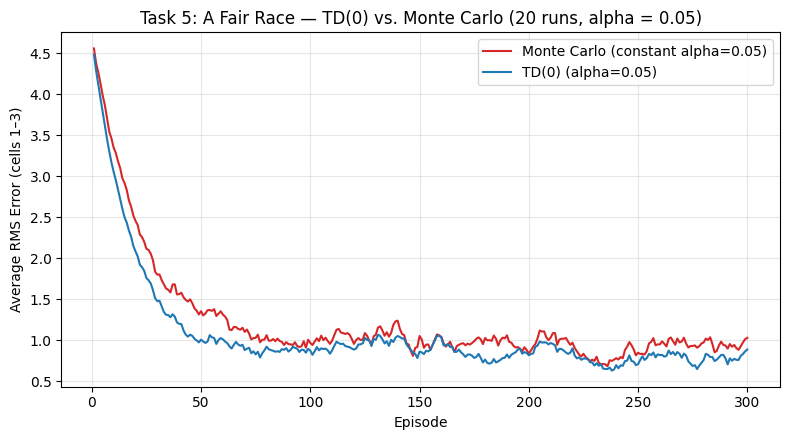

Episodes   Average RMS MC     Average RMS TD(0)  Smaller error 
------------------------------------------------------------
10         3.3511             3.0560             TD(0)         
50         1.3568             1.0100             TD(0)         
100        0.9709             0.8766             TD(0)         
300        1.0318             0.8900             TD(0)         


In [12]:
# Task 5 (b): 20 runs x 300 episodes, the same episodes for both methods
N_RUNS = 20
N_EPISODES = 300
ALPHA = 0.05

def calc_rms(V):
    return np.sqrt(np.mean((V[1:4] - V_exact_U[1:4])**2))

mc_rms_runs = np.zeros((N_RUNS, N_EPISODES))
td_rms_runs = np.zeros((N_RUNS, N_EPISODES))

for k in range(N_RUNS):
    run_seed = SEED + k
    env = CorridorEnv(seed=run_seed)
    rng = np.random.default_rng(run_seed)
    V_mc = np.zeros(N_STATES)
    V_td = np.zeros(N_STATES)
    for ep in range(N_EPISODES):
        states, actions, rewards, next_states = run_episode(env, random_policy, rng)
        mc_alpha_episode(V_mc, states, rewards, ALPHA, GAMMA)
        td0_episode(V_td, states, rewards, next_states, ALPHA, GAMMA)
        mc_rms_runs[k, ep] = calc_rms(V_mc)
        td_rms_runs[k, ep] = calc_rms(V_td)

avg_mc_rms = np.mean(mc_rms_runs, axis=0)
avg_td_rms = np.mean(td_rms_runs, axis=0)

# Plot RMS error curves
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, N_EPISODES + 1), avg_mc_rms, label="Monte Carlo (constant alpha=0.05)", color="#d62728", lw=1.5)
plt.plot(range(1, N_EPISODES + 1), avg_td_rms, label="TD(0) (alpha=0.05)", color="#1f77b4", lw=1.5)
plt.xlabel("Episode")
plt.ylabel("Average RMS Error (cells 1–3)")
plt.title(f"Task 5: A Fair Race — TD(0) vs. Monte Carlo (20 runs, alpha = 0.05)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Table 10 output
checkpoints = [10, 50, 100, 300]
print(f"{'Episodes':<10} {'Average RMS MC':<18} {'Average RMS TD(0)':<18} {'Smaller error':<14}")
print("-" * 60)
for ep in checkpoints:
    mc_val = avg_mc_rms[ep - 1]
    td_val = avg_td_rms[ep - 1]
    winner = "TD(0)" if td_val < mc_val else "Monte Carlo"
    print(f"{ep:<10} {mc_val:<18.4f} {td_val:<18.4f} {winner:<14}")

| Episodes | Average RMS error, MC | Average RMS error, TD(0) | Smaller error |
|---|---|---|---|
| 10 | **3.351** | **3.056** | **TD(0)** |
| 50 | **1.357** | **1.010** | **TD(0)** |
| 100 | **0.971** | **0.877** | **TD(0)** |
| 300 | **1.032** | **0.890** | **TD(0)** |

**Questions**

1. Which method had the smaller error in your race, and at which numbers of episodes? Quote Table 10.

   **Answer:** **TD(0) had the smaller error across all checkpoints in the race.** As quoted from Table 10:
   - At 10 episodes: TD(0) error is **3.056** vs. MC's **3.351** (TD smaller).
   - At 50 episodes: TD(0) error is **1.010** vs. MC's **1.357** (TD smaller).
   - At 100 episodes: TD(0) error is **0.877** vs. MC's **0.971** (TD smaller).
   - At 300 episodes: TD(0) error is **0.890** vs. MC's **1.032** (TD smaller).

2. The MC target $G_t$ depends on every random slip and coin flip until the end of the episode, while the TD target depends on only one step. Use this to explain your result.

   **Answer:** The full return $G_t = R_{t+1} + \gamma R_{t+2} + \dots$ compounds the stochasticity of dozens of random actions and slip events over the duration of the trajectory, creating high sample variance in the target. In contrast, the TD(0) target $R_{t+1} + \gamma V(S_{t+1})$ only depends on a single step's transition, replacing subsequent random events with the smoother expectation encoded in $V(S_{t+1})$. Because TD targets have significantly lower variance, TD learns much more efficiently and maintains lower error throughout training.

3. In Lab 7, MC averaged all its returns instead of using a fixed α. Why do we give both methods the same α here?

   **Answer:** Using a sample-average update ($1/N$) in MC would conflate the algorithmic comparison with differing effective step-size schedules (since $1/N$ decays toward 0, whereas constant $\alpha$ does not). To establish a rigorous, fair "apples-to-apples" comparison where the **only** difference is the update target ($G_t$ versus $R_{t+1} + \gamma V(S_{t+1})$), both methods must process identical episodes using the exact same step-size $\alpha$.

4. Did both curves stop improving at some level? Relate this to what you found about a fixed α in Task 4.

   **Answer:** **Yes, both curves plateaued around 100–150 episodes** (with RMS hovering near $\approx 0.9$ for TD and $\approx 1.0$ for MC) and ceased improving further. This directly connects to Task 4: with a fixed $\alpha = 0.05$, the update step size never decays to zero. Each new episode continues to jostle the estimates around the true values proportional to the residual variance of the target, reaching an asymptotic error floor governed by $\alpha$.

---
## Part 4: Learning from Unfinished Episodes

### Task 6: When the Battery Runs Out

The robot's battery now allows at most **4 steps** per episode. Many episodes therefore stop before the robot reaches G or F. `run_episode_battery(env, policy, rng, battery=4)` plays such an episode and also returns `finished`.

- **Monte Carlo** needs the return $G_t$, which is only known if the episode reached G or F, so it can use **only finished episodes**.
- **TD** can update after every step it has seen. When an episode stops early, the last cell is **not** terminal, so its TD target still uses $\gamma V(S_{t+1})$.

**Predict first.** About what fraction of the episodes do you think will finish within 4 steps under $\pi_U$? Which method will be more accurate?

**Prediction:** We expect roughly **50% to 60%** of episodes to finish within 4 steps from cell 2 (since reaching cell 4 or 0 requires at least 2 consecutive successful steps in one direction, while slips and direction reversals will stall the robot in cells 1–3 past the 4-step limit). We expect **TD(0) to be far more accurate**. TD can learn unbiased one-step transitions from all 1000 episodes (including incomplete ones), whereas Monte Carlo is forced to discard all unfinished episodes, introducing severe selection bias.

**(a)** For $\pi_U$ with $\alpha = 0.05$, play 1000 battery-limited episodes (seed SEED). Update TD on every episode and MC (constant α, first visit) on finished episodes only. Record the number of finished episodes and the number of updates each method made, and complete Table 11.

In [13]:
# Task 6 (a): 1000 battery-limited episodes; TD on all of them, MC on finished ones only.
env = CorridorEnv(seed=SEED)
rng = np.random.default_rng(SEED)

V_mc = np.zeros(N_STATES)
V_td = np.zeros(N_STATES)

mc_episodes_used = 0
mc_updates = 0
td_episodes_used = 1000
td_updates = 0
finished_count = 0

for ep in range(1000):
    states, actions, rewards, next_states, finished = run_episode_battery(env, random_policy, rng, battery=4)
    # TD updates on every transition of every episode
    for t in range(len(states)):
        td0_update(V_td, states[t], rewards[t], next_states[t], 0.05, GAMMA)
        td_updates += 1

    # MC updates only on finished episodes
    if finished:
        finished_count += 1
        mc_episodes_used += 1
        G = returns_backward(rewards, GAMMA)
        visited = set()
        for t in range(len(states)):
            s = states[t]
            if s not in visited:
                visited.add(s)
                V_mc[s] += 0.05 * (G[t] - V_mc[s])
                mc_updates += 1

rms_mc = np.sqrt(np.mean((V_mc[1:4] - V_exact_U[1:4])**2))
rms_td = np.sqrt(np.mean((V_td[1:4] - V_exact_U[1:4])**2))

print(f"Episodes that finished within 4 steps: {finished_count} out of 1000\n")
print(f"{'Measure':<26} {'Monte Carlo':<14} {'TD(0)':<14}")
print("-" * 54)
print(f"{'Episodes used':<26} {mc_episodes_used:<14} {td_episodes_used:<14}")
print(f"{'Number of updates made':<26} {mc_updates:<14} {td_updates:<14}")
print(f"{'Estimate of V(1)':<26} {V_mc[1]:<14.4f} {V_td[1]:<14.4f}")
print(f"{'Estimate of V(2)':<26} {V_mc[2]:<14.4f} {V_td[2]:<14.4f}")
print(f"{'Estimate of V(3)':<26} {V_mc[3]:<14.4f} {V_td[3]:<14.4f}")
print(f"{'RMS error over cells 1–3':<26} {rms_mc:<14.4f} {rms_td:<14.4f}")

Episodes that finished within 4 steps: 577 out of 1000

Measure                    Monte Carlo    TD(0)         
------------------------------------------------------
Episodes used              577            1000          
Number of updates made     1214           3255          
Estimate of V(1)           -8.4940        -7.1955       
Estimate of V(2)           -2.4635        -3.9585       
Estimate of V(3)           7.2566         1.2632        
RMS error over cells 1–3   2.7358         1.0549        


| Measure | Monte Carlo | TD(0) |
|---|---|---|
| Episodes used | **577** | **1000** |
| Number of updates made | **1214** | **3255** |
| Estimate of V(1) | **–8.494** | **–7.195** |
| Estimate of V(2) | **–2.464** | **–3.958** |
| Estimate of V(3) | **+7.257** | **+1.263** |
| RMS error over cells 1–3 | **2.736** | **1.055** |

Episodes that finished within 4 steps: **577** out of 1000

**(b)** Plot both estimates against the exact values with `plot_values`.

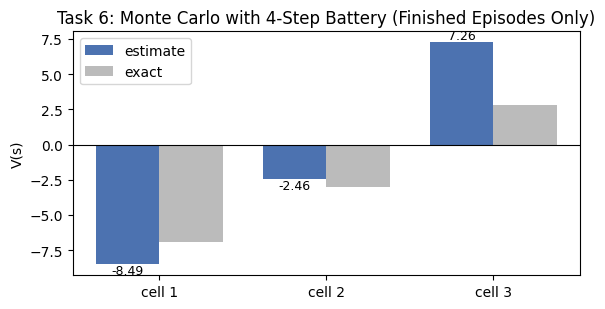

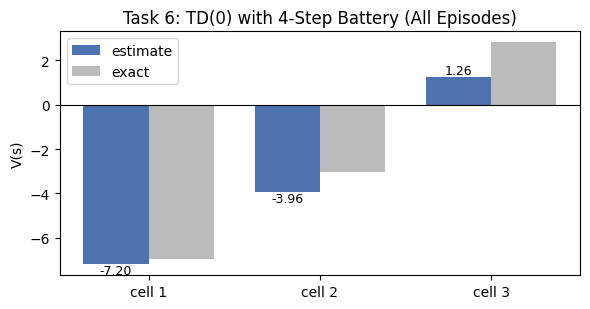

In [14]:
# Task 6 (b): plot_values for the MC and TD estimates of Task 6
plot_values(V_mc, V_ref=V_exact_U, title="Task 6: Monte Carlo with 4-Step Battery (Finished Episodes Only)")
plot_values(V_td, V_ref=V_exact_U, title="Task 6: TD(0) with 4-Step Battery (All Episodes)")

**Questions**

1. How many episodes did Monte Carlo have to throw away? What fraction of the robot's experience was lost?

   **Answer:** Monte Carlo had to throw away **423 episodes** out of 1000 (i.e. **42.3% of all episodes**). In terms of individual transitions, TD performed 3255 updates across all steps, while MC executed only 1214 updates. Consequently, **62.7% of the robot's step-level interaction experience was completely discarded** by Monte Carlo.

2. The MC estimate of V(3) is far too high. The finished episodes are not a fair sample of all episodes: which kind of episode finishes within 4 steps from cell 3? Explain why this biases the estimate.

   **Answer:** Under $\pi_U$, any episode starting from cell 2 that reaches cell 3 must take at least 1 step. To finish within 4 steps, it must transition from cell 3 to the goal $G$ (cell 4) almost immediately (collecting the $+10$ reward). If the robot in cell 3 instead moves left or slips repeatedly, the 4-step battery expires before reaching a terminal state, and that entire trajectory is thrown away! Consequently, Monte Carlo only sees the "lucky" quick-win episodes that enter $G$, discarding all the episodes that wandered or drifted left. This survivor bias drastically inflates the returns observed from cell 3, driving $V(3)$ to $+7.257$ (compared to the true value of $+2.816$).

3. Why can TD still learn correctly from an episode that stopped at, say, cell 1? What does it use in place of the missing future?

   **Answer:** TD updates transition-by-transition: for any step $S_t \to S_{t+1}$ with reward $R_{t+1}$, the update $V(S_t) \leftarrow V(S_t) + \alpha [R_{t+1} + \gamma V(S_{t+1}) - V(S_t)]$ requires only local transition information. When the battery terminates an episode at cell 1, cell 1 is not terminal, so TD simply uses its current estimate $\gamma V(1)$ as a proxy for all future rewards. It does not need the episode to reach $G$ or $F$ to perform legitimate, informative updates.

4. Name one real task where episodes are very long or never end. Which method would you use, and why?

   **Answer:** Examples include **autonomous server load balancing / cloud resource scheduling**, **industrial chemical plant process control**, or **financial algorithmic trading portfolio management**. These are continuing (non-episodic) tasks that run indefinitely without natural terminal states. I would use **TD learning**, because Monte Carlo is fundamentally incapable of learning in continuing tasks (as it requires waiting for episode termination to compute returns). TD can learn continuously online at each control interval from every single transition.

---
## Part 5: Summary and Reflection

### Task 7: Summary and Reflection

**(a)** Table 12: Dynamic programming, Monte Carlo and TD compared

| Property | DP (Lab 5) | Monte Carlo (Lab 7) | TD(0) (Lab 8) |
|---|---|---|---|
| Needs the rules (P and R) | **Yes** (model-based) | **No** (model-free) | **No** (model-free) |
| When the estimate is updated | **Offline** (sweeps over state space) | **Offline** (at the end of each episode) | **Online** (step-by-step after each transition) |
| Target of the update | $\sum_a \pi(a\mid s) \sum_{s'} P(s'\mid s, a)[R(s,a,s') + \gamma V(s')]$ | $G_t = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1}$ | $R_{t+1} + \gamma V(S_{t+1})$ |
| Can use unfinished episodes | **N/A** (does not use sample episodes) | **No** (cannot calculate return $G_t$) | **Yes** (bootstraps using $\gamma V(S_{t+1})$) |
| Main source of error in your results | None (exact linear system solution) | High sample variance of full returns; severe truncation bias | Bootstrapping bias from initial zeros; asymptotic variance from fixed $\alpha$ |

**(b)** In no more than 150 words, explain what TD learning offers compared with Monte Carlo, and name one weakness. Quote at least two numbers from your own results. State what would have to change to move from estimating a policy to improving it with TD.

**Answer:**
TD learning bridges dynamic programming and Monte Carlo by learning model-free from experience while bootstrapping from subsequent estimates. This eliminates the wait for episode completion and drastically reduces variance: in Task 5's 20-run race ($\alpha=0.05$), TD reached an RMS error of **1.0100** at 50 episodes versus MC's **1.3568**, maintaining superiority through 300 episodes (**0.8900** vs **1.0318**). Furthermore, in Task 6's battery-limited setting, MC lost **42.3%** of episodes, heavily biasing $V(3)$ to **7.257** (exact 2.816, RMS **2.736**), whereas TD learned from all 3255 transitions (RMS **1.055**).

A weakness of TD is bootstrapping bias: initial errors in $V(S_{t+1})$ distort early updates. To move from prediction to control, we must estimate action-values $Q(s, a)$ rather than state-values $V(s)$ and interleave evaluation with policy improvement (e.g., using $\epsilon$-greedy action selection via SARSA or Q-learning).

lab ended
